# Data Engineering: Stream Processing from Scratch

> **Who is this for:** you know Python functions, dictionaries and classes, and you have met message queues or Kafka as a concept ([message queues](../../16_Deployment/message_queues/01_message_queues.ipynb), [data engineering for ML](01_data_engineering.ipynb)). You want to understand what stream processors such as Flink, Kafka Streams and Spark Structured Streaming actually do, by building one. It is also for students in a "Big Data" or "Distributed Systems" course and for data/ML-engineering interviews ("what is a watermark?", "how do you get exactly-once?").
>
> **What you will learn:**
> - Batch vs stream; **event time vs processing time**; out-of-order and **late** data
> - A Python event generator with realistic delays, and a stream processor built on `queue` and `asyncio`
> - **Tumbling, sliding and session windows**, **watermarks** and **allowed lateness**, implemented and checked against batch results
> - **Stateful operators**: per-key aggregates, **deduplication with a TTL**, **stream–table (temporal) joins**
> - **Delivery semantics**: at-most-once, at-least-once, exactly-once; **idempotent sinks** in SQLite; **checkpointing** and recovery after a simulated crash
> - **Backpressure** with bounded queues
> - **Streaming features** for online ML, computed point-in-time correctly
> - How **Kafka, Flink and Spark Structured Streaming** map to every piece you built
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb) (classes, dictionaries); [pandas](../../02_Data_Analysis/03_pandas.ipynb); [message queues](../../16_Deployment/message_queues/01_message_queues.ipynb); [transactions](../00_dbms_fundamentals/05_transactions_and_concurrency_control.ipynb) and [recovery](../00_dbms_fundamentals/06_recovery_and_storage.ipynb) from the DBMS track help for Section 5; [concurrency and async](../../23_Software_Engineering/05_concurrency_and_async.ipynb) helps for Sections 2 and 6.
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet, no Kafka or Flink needed: everything is pure Python plus pandas and SQLite (files go to a temporary folder that is deleted at the end). The whole notebook runs in well under a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Akidau et al., "The Dataflow Model" (VLDB 2015) and Akidau, Chernyak & Lax, *Streaming Systems* (O'Reilly).

## Explained simply

**Batch processing** waits until all the data has arrived and then computes the answer, like counting all the votes after the polls close. **Stream processing** updates the answer continuously as each new piece of data arrives, like a live scoreboard. The hard part is that data does not arrive in the order it happened: a phone in a tunnel sends its messages minutes later, so "what happened at 10:00" may only reach you at 10:05. A stream processor therefore has to decide **how long to wait** for stragglers before announcing a result (that waiting rule is called a **watermark**). It also has to survive crashes without losing or double-counting anything. Think of a post office sorting letters by the date they were *written*, not the date they *arrived*: it holds the "Monday" pile open for a while in case late Monday letters show up, then closes it. Or think of a cashier who must not charge you twice when the card machine retries a payment.

**Tiny example.** Clicks happen at 10:00:01, 10:00:04 and 10:00:08, but arrive at 10:00:02, 10:00:09 and 10:00:08. We count clicks per 5-second window. If we close the window [10:00:00, 10:00:05) as soon as we see the 10:00:08 click, we report **1 click** and miss the 10:00:04 click that arrives a second later. If we wait 5 seconds before closing windows, we report the correct **2 clicks**, but the answer comes out later. Waiting longer = more correct but slower.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Event time vs processing time | when something happened vs when we heard about it | phone apps that sync later, IoT sensors, click logs |
| Watermark | "I believe I have now seen everything that happened before time T" | Flink, Spark Structured Streaming, Google Dataflow |
| Exactly-once | every event affects the result once, even after crashes and retries | payments, ad billing, real-time features for fraud models |

### How this notebook is different from related notebooks
[`message_queues`](../../16_Deployment/message_queues/01_message_queues.ipynb) introduces Kafka, Celery and Redis Streams as **transport**. [`12_online_learning/02`](../../03_Machine_Learning/12_online_learning/02_industry_streaming_model_updates.ipynb) updates a **model** on a stream. [Advanced algorithms 06](../../00_AI_Fundamentals/advanced_algorithms/06_streaming_and_sketching_algorithms.ipynb) covers **sketches** (approximate counting in tiny memory). Here we build the **processing engine** itself: time, windows, state, fault tolerance and flow control. [Notebook 03](03_spark_locally.ipynb) showed the Spark Structured Streaming API; this notebook explains what happens inside it.

## Table of contents
0. Setup
1. Batch vs stream, event time vs processing time
2. A stream processor with `queue` and threads
3. Windows and watermarks
4. Stateful operators: aggregates, deduplication, stream–table joins
5. Delivery semantics, idempotent sinks and checkpoints
6. Backpressure with bounded queues (`asyncio`)
7. Streaming features for online ML
8. How Kafka, Flink and Spark Structured Streaming map to this
9. How this connects to modern AI
10. Recap, practice problems, further reading

---
## 0. Setup

In [1]:
import asyncio, bisect, heapq, json, math, queue, shutil, sqlite3, tempfile, threading, time
from collections import Counter, defaultdict, deque, namedtuple
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

WORK = Path(tempfile.mkdtemp(prefix="streams_"))      # SQLite files go here; deleted at the end
Event = namedtuple("Event", "event_id user kind amount event_time arrival")
print("pandas", pd.__version__, "| sqlite", sqlite3.sqlite_version)

pandas 2.3.3 | sqlite 3.45.1


---
## 1. Batch vs stream, event time vs processing time

> 💬 **In plain English:** every event has the time it happened and the time we heard about it, and the two often disagree.

A **bounded** dataset has an end (yesterday's log file); an **unbounded** dataset never ends (a live click feed). **Batch processing** computes over bounded data; **stream processing** computes over unbounded data, incrementally, producing results while data keeps arriving.

Every event has (at least) two timestamps:

- **event time**: when the event actually happened (set by the device that produced it);
- **processing time**: when the stream processor sees it.

The difference is the **event-time skew** (delay). Delays vary (networks, retries, devices that go offline), so events arrive **out of order**. An event is **late** if it arrives after the system has already decided that its time period is complete.

### 1.1 A realistic event generator

Users produce view/click/purchase events at about 10 per second (a Poisson process). Each event gets a network delay (usually a fraction of a second), 3% of events come from a phone that was **offline** and arrive 5–40 s late, and 2% are **re-sent** by the client a few seconds later with the same `event_id` (a retry after a timeout). The stream is the list of events **in arrival order**.

3,060 events over 304 s of event time, 100 users
duplicates (same event_id): 60
delay: median 0.31 s, 99th pct 25.8 s, max 40.1 s
out-of-order arrivals (event time older than an event already seen): 47.3%
event_id user  kind  amount  event_time  arrival  delay
  e00002 u011 click     0.0       0.172    0.295  0.123
  e00000 u001 click     0.0       0.068    0.383  0.315
  e00004 u020  view     0.0       0.227    0.622  0.395
  e00001 u021 click     0.0       0.170    0.669  0.499
  e00007 u032  view     0.0       0.533    0.815  0.282


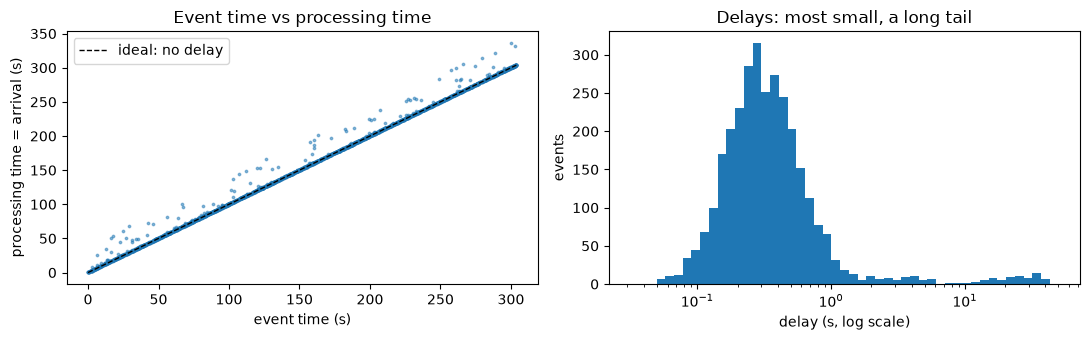

In [2]:
def make_events(n=3000, rate=10.0, n_users=100, seed=0):
    rng = np.random.default_rng(seed)
    event_time = np.cumsum(rng.exponential(1 / rate, n))                    # Poisson process, ~10 events/s
    delay = rng.lognormal(np.log(0.3), 0.6, n)                              # typical network delay ~0.3 s
    offline = rng.random(n) < 0.03
    delay[offline] += rng.uniform(5, 40, offline.sum())                     # phone offline: very late
    p_user = 1 / np.arange(1, n_users + 1) ** 0.8; p_user /= p_user.sum()  # some users are more active
    users = rng.choice(n_users, n, p=p_user)
    kind = rng.choice(["view", "click", "purchase"], n, p=[0.70, 0.22, 0.08])
    amount = np.where(kind == "purchase", rng.gamma(2.0, 15.0, n).round(2), 0.0)
    events = [Event(f"e{i:05d}", f"u{users[i]:03d}", str(kind[i]), float(amount[i]),
                    round(float(event_time[i]), 3), round(float(event_time[i] + delay[i]), 3)) for i in range(n)]
    for i in rng.choice(n, int(0.02 * n), replace=False):                  # client retries: same event_id
        e = events[i]
        events.append(e._replace(arrival=round(e.arrival + rng.uniform(1, 5), 3)))
    return sorted(events, key=lambda e: e.arrival)                          # the stream = arrival order

stream = make_events()
df = pd.DataFrame(stream, columns=Event._fields)
df["delay"] = df.arrival - df.event_time
prev_max = df.event_time.cummax().shift(fill_value=-1)
print(f"{len(stream):,} events over {df.event_time.max():.0f} s of event time, {df.user.nunique()} users")
print(f"duplicates (same event_id): {df.event_id.duplicated().sum()}")
print(f"delay: median {df.delay.median():.2f} s, 99th pct {df.delay.quantile(0.99):.1f} s, max {df.delay.max():.1f} s")
print(f"out-of-order arrivals (event time older than an event already seen): {(df.event_time < prev_max).mean():.1%}")
print(df.head(5).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].scatter(df.event_time, df.arrival, s=3, alpha=0.5)
ax[0].plot([0, df.event_time.max()], [0, df.event_time.max()], "k--", lw=1, label="ideal: no delay")
ax[0].set_xlabel("event time (s)"); ax[0].set_ylabel("processing time = arrival (s)")
ax[0].set_title("Event time vs processing time"); ax[0].legend()
ax[1].hist(df.delay, bins=np.logspace(-1.5, 1.7, 50)); ax[1].set_xscale("log")
ax[1].set_xlabel("delay (s, log scale)"); ax[1].set_ylabel("events"); ax[1].set_title("Delays: most small, a long tail")
plt.tight_layout(); plt.show()

**What just happened?** Most points lie just above the diagonal (a fraction of a second late), but a cloud of points sits far above it: events that happened at one time and reached us 5–40 seconds later. Almost half of all arrivals are out of order (an event arrives after an event that happened later), which is normal for real event streams. Any per-minute count computed in **arrival order** would put those events in the wrong minute.

> 🎓 **Exam / interview tip:** for business metrics ("revenue per hour", "clicks per minute"), group by **event time**. Processing-time windows are simpler and have no lateness problem, but their results change if the pipeline is slow or replayed, so they are only right for operational metrics (e.g. "requests the server handled per second").

For the windowing sections we first remove the client retries (Section 4.2 shows how to do that in a stream), so that every event counts once:

In [3]:
seen = set()
clean = [e for e in stream if not (e.event_id in seen or seen.add(e.event_id))]   # keep first arrival
print(len(stream), "events ->", len(clean), "after removing retries")

3060 events -> 3000 after removing retries


---
## 2. A stream processor with `queue` and threads

> 💬 **In plain English:** a stream processor is a chain of small workers passing events through queues.

A stream processor is a pipeline of **operators** connected by **queues**: a **source** reads events (from Kafka, a socket, a file), operators transform them, a **sink** writes results. Each stage can run in its own thread or process. Python's `queue.Queue` is a thread-safe FIFO; a special **sentinel** value (`None`) tells the next stage that the stream ended (a real stream never ends, but tests do).

```
  source thread ──put──> [ queue ] ──get──> operator thread ──> sink (list / database)
```

In [4]:
def source(events, out_q):
    for e in events:                  # in production: for msg in kafka_consumer: ...
        out_q.put(e)
    out_q.put(None)                   # end-of-stream sentinel

def count_per_kind(in_q, results):
    counts = Counter()
    while (e := in_q.get()) is not None:
        counts[e.kind] += 1           # a stateful operator: running count per key
    results.update(counts)

q, results = queue.Queue(maxsize=100), Counter()
threads = [threading.Thread(target=source, args=(clean, q)), threading.Thread(target=count_per_kind, args=(q, results))]
for t in threads: t.start()
for t in threads: t.join()
assert results == Counter(e.kind for e in clean)
print("threaded pipeline result:", dict(results), "(matches a plain Counter)")

threaded pipeline result: {'click': 651, 'view': 2091, 'purchase': 258} (matches a plain Counter)


**What just happened?** Two threads ran concurrently, connected by a queue of at most 100 events, and produced the same counts as a plain loop. Everything below uses the same structure; to keep the code short we call operators directly in a loop (`for e in stream: op.process(e)`), which is exactly what each operator thread does with the events it takes from its input queue.

---
## 3. Windows and watermarks

> 💬 **In plain English:** chop the endless stream into time buckets, and decide how long to wait for late arrivals before closing a bucket.

### 3.1 Window types

A **window** groups an unbounded stream into finite chunks by event time:

| type | definition | example (size 10 s) |
|---|---|---|
| **tumbling** | fixed size, no overlap: $[k\cdot s,\ (k+1)\cdot s)$; each event is in exactly 1 window | [0,10), [10,20), … |
| **sliding** (hopping) | size $s$, a new window every slide $d < s$; each event is in $s/d$ windows | size 30, slide 10: [0,30), [10,40), [20,50), … |
| **session** | per key, a burst of activity separated by a gap of inactivity ≥ $g$; data-dependent sizes | a user's visit ends after 15 s without events |

By hand: an event at $t = 37$ s is in tumbling window [30, 40), and in sliding windows (size 30, slide 10) [10, 40), [20, 50) and [30, 60).

In [5]:
def tumbling(t, size):
    start = math.floor(t / size) * size
    return [(start, start + size)]

def sliding(t, size, slide):
    last_start = math.floor(t / slide) * slide                         # latest window that contains t
    return [(s, s + size) for s in range(last_start - size + slide, last_start + 1, slide) if s <= t < s + size]

assert tumbling(37, 10) == [(30, 40)]
assert sliding(37, 30, 10) == [(10, 40), (20, 50), (30, 60)]
# brute-force check of sliding() on random times
for t in np.random.default_rng(1).uniform(0, 500, 2000):
    brute = [(s, s + 30) for s in range(-30, 600, 10) if s <= t < s + 30]
    assert sliding(t, 30, 10) == brute
print("tumbling and sliding window assignment verified")

tumbling and sliding window assignment verified


### 3.2 Watermarks

In event time, a window $[a, b)$ can only be finalised when we believe no more events with time $< b$ will arrive. A **watermark** $W$ is the processor's estimate of that: "all events with event time $< W$ have arrived". The simplest strategy, used by Flink's `forBoundedOutOfOrderness` and Spark's `withWatermark`, is

$$W = (\text{maximum event time seen so far}) - \text{bound}.$$

A window $[a, b)$ **fires** (emits its result) when $W \ge b$. An event with event time $t$ that arrives when $t < W$ and whose window has already fired is **late**. With **allowed lateness** $L$, the window's state is kept until $W \ge b + L$: late events within that time update the window and an **updated** result is emitted; events after that are **dropped** (or sent to a **side output** for separate handling).

Worked example (tumbling 10 s windows, bound 5 s):

| arrives | event time | max seen | watermark | action |
|---|---|---|---|---|
| 1st | 3 | 3 | −2 | add to [0,10) |
| 2nd | 12 | 12 | 7 | add to [10,20) |
| 3rd | 9 | 12 | 7 | 9 ≥ 7: not late, add to [0,10) |
| 4th | 16 | 16 | 11 | add to [10,20); W = 11 ≥ 10 → **fire [0,10) = 2** |
| 5th | 8 | 16 | 11 | [0,10) already fired → **late** (dropped if L = 0) |

In [6]:
class WindowedCount:
    # Event-time window counts with a bounded-out-of-orderness watermark and allowed lateness.
    def __init__(self, assign, bound, lateness=0.0, emit=None):
        self.assign, self.bound, self.lateness = assign, bound, lateness
        self.max_t = -math.inf          # largest event time seen so far
        self.state = {}                 # open window -> count
        self.fired = set()              # windows that already emitted a result
        self.dropped = 0                # (event, window) pairs that were too late
        self.max_state = 0
        self.emit = emit or (lambda *args: None)

    @property
    def watermark(self):
        return self.max_t - self.bound

    def process(self, e):
        for w in self.assign(e.event_time):
            if w[1] + self.lateness <= self.watermark:      # window closed for good: too late
                self.dropped += 1
                continue
            self.state[w] = self.state.get(w, 0) + 1
            if w in self.fired:                             # late, but within allowed lateness
                self.emit(w, self.state[w], e.arrival, "late update")
        self.max_t = max(self.max_t, e.event_time)
        self._on_watermark(e.arrival)
        self.max_state = max(self.max_state, len(self.state))

    def _on_watermark(self, now):
        wm = self.watermark
        for w in sorted(self.state):
            if w not in self.fired and w[1] <= wm:          # the watermark passed the window end: fire
                self.fired.add(w)
                self.emit(w, self.state[w], now, "on time")
        for w in [w for w in self.state if w[1] + self.lateness <= wm]:
            del self.state[w]                               # purge state after the lateness horizon

    def flush(self, now):                                   # end of a finite stream: watermark -> +infinity
        self.max_t = math.inf
        self._on_watermark(now)

def run_windows(events, assign, bound, lateness=0.0):
    out = []
    op = WindowedCount(assign, bound, lateness, emit=lambda w, c, now, kind: out.append((w, c, now, kind)))
    for e in events:
        op.process(e)
    op.flush(events[-1].arrival)
    return pd.DataFrame(out, columns=["window", "count", "emitted_at", "kind"]), op

def batch_truth(events, assign):
    # The correct answer: what a batch job over the complete data would compute.
    return Counter(w for e in events for w in assign(e.event_time))

tumble10 = lambda t: tumbling(t, 10)
truth10 = batch_truth(clean, tumble10)
res, op = run_windows(clean, tumble10, bound=5)
first = res[res.kind == "on time"].set_index("window")["count"]
correct = sum(first.get(w) == truth10[w] for w in truth10)
print(f"bound=5 s: {len(truth10)} windows, {correct} correct at first firing, "
      f"{op.dropped} late events dropped ({op.dropped / len(clean):.1%}), max open windows {op.max_state}")
print(res.head(4).to_string(index=False))

bound=5 s: 31 windows, 6 correct at first firing, 62 late events dropped (2.1%), max open windows 2
  window  count  emitted_at    kind
 (0, 10)     89      15.299 on time
(10, 20)     80      25.103 on time
(20, 30)     85      35.380 on time
(30, 40)     98      45.282 on time


**What just happened?** With a 5-second bound only about 2% of events are dropped: the "offline phone" events delayed by more than about 5 s. But those events are spread over the whole stream, roughly two or three in every 10-second window, so only 6 of the 31 windows are *exactly* right at their first firing; the others are short by a few events out of about 100. The state stays tiny: at most 2 windows are open at any moment, however long the stream runs. Each result row also records **when** it was emitted (in processing time), which lets us measure latency.

### 3.3 The completeness–latency trade-off

How should we choose the bound? We sweep it and measure (a) the share of windows whose first result is correct, (b) the share of events dropped, and (c) the average latency from the window end (in event time) to the moment its result is emitted (in processing time).

 bound (s)  windows correct at first result  events dropped  mean latency (s)
       0.0                            0.097           0.032             1.224
       0.5                            0.161           0.025             1.655
       1.0                            0.194           0.022             2.181
       2.0                            0.194           0.022             3.127
       5.0                            0.194           0.021             7.018
      10.0                            0.226           0.019            11.744
      20.0                            0.419           0.010            21.942
      45.0                            1.000           0.000            46.533


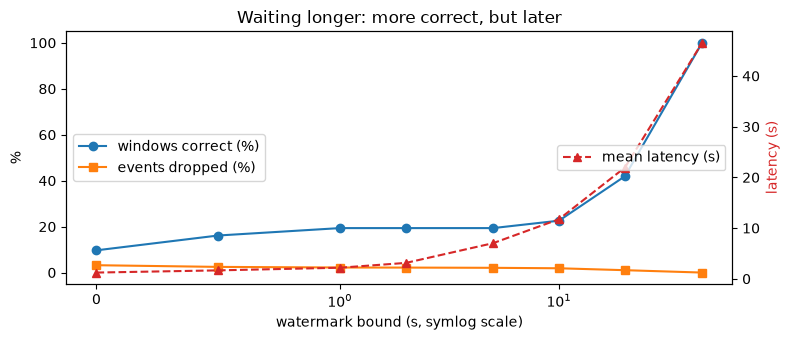

In [7]:
sweep = []
for bound in [0, 0.5, 1, 2, 5, 10, 20, 45]:
    res, op = run_windows(clean, tumble10, bound=bound)
    on_time = res[res.kind == "on time"]
    first = on_time.set_index("window")["count"]
    sweep.append({"bound (s)": bound,
                  "windows correct at first result": np.mean([first.get(w) == truth10[w] for w in truth10]),
                  "events dropped": op.dropped / len(clean),
                  "mean latency (s)": (on_time.emitted_at - on_time.window.map(lambda w: w[1])).mean()})
sweep = pd.DataFrame(sweep)
print(sweep.round(3).to_string(index=False))

fig, ax1 = plt.subplots(figsize=(8, 3.5))
ax1.plot(sweep["bound (s)"], sweep["windows correct at first result"] * 100, "o-", label="windows correct (%)")
ax1.plot(sweep["bound (s)"], sweep["events dropped"] * 100, "s-", label="events dropped (%)")
ax1.set_xscale("symlog", linthresh=1); ax1.set_xlabel("watermark bound (s, symlog scale)"); ax1.set_ylabel("%")
ax2 = ax1.twinx(); ax2.plot(sweep["bound (s)"], sweep["mean latency (s)"], "^--", color="tab:red", label="mean latency (s)")
ax2.set_ylabel("latency (s)", color="tab:red")
ax1.legend(loc="center left"); ax2.legend(loc="center right"); ax1.set_title("Waiting longer: more correct, but later")
plt.tight_layout(); plt.show()

**What just happened?** With bound 0 (fire as soon as a newer event appears), results come out about a second after each window ends, but more events are dropped and fewer than 10% of windows are exact. Each increase of the bound drops fewer events and adds the same amount of latency to **every** result. Because the long-delayed "offline phone" events are scattered over the whole stream, almost every window contains one, so the share of exactly-correct windows only reaches 100% when the bound exceeds the longest delay (45 s), and then every result is about 45 s late. That is the fundamental trade-off of event-time processing: completeness against latency. **Allowed lateness** offers a middle way: fire early with a small bound, then emit corrections.

In [8]:
configs = [("bound 2 s, no lateness", 2, 0), ("bound 2 s + allowed lateness 45 s", 2, 45), ("bound 45 s", 45, 0)]
rows = []
for name, bound, lateness in configs:
    res, op = run_windows(clean, tumble10, bound=bound, lateness=lateness)
    final = res.groupby("window")["count"].last()                          # last emitted value per window
    rows.append({"config": name,
                 "first results correct": np.mean([res[res.kind == "on time"].set_index("window")["count"].get(w) == truth10[w] for w in truth10]),
                 "final results correct": np.mean([final[w] == truth10[w] for w in truth10]),
                 "late updates emitted": int((res.kind == "late update").sum()),
                 "events dropped": op.dropped, "max open windows (state)": op.max_state})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                           config  first results correct  final results correct  late updates emitted  events dropped  max open windows (state)
           bound 2 s, no lateness                  0.194                  0.194                     0              65                         2
bound 2 s + allowed lateness 45 s                  0.194                  1.000                    65               0                         6
                       bound 45 s                  1.000                  1.000                     0               0                         6


**What just happened?** "Bound 2 s + allowed lateness 45 s" gives early results (like bound 2 s) **and** eventually correct results (like bound 45 s), at the price of emitting update records (the sink must **upsert**, not append) and keeping more windows in state. This is the model of Flink's `allowedLateness` and Google Dataflow's triggers with accumulating panes.

### 3.4 Sliding and session windows

In [9]:
slide30 = lambda t: sliding(t, 30, 10)
res_sl, op_sl = run_windows(clean, slide30, bound=45)                 # bound above the largest delay
truth_sl = batch_truth(clean, slide30)
assert dict(res_sl.groupby("window")["count"].last()) == dict(truth_sl) and op_sl.dropped == 0
print(f"sliding windows (30 s every 10 s): {len(truth_sl)} windows, all equal to the batch result")

class SessionWindows:
    # Per-key session windows (gap g): merge overlapping [t, t+g) intervals; fire when the watermark passes the end.
    def __init__(self, gap, bound):
        self.gap, self.bound = gap, bound
        self.max_t, self.open, self.out, self.dropped = -math.inf, defaultdict(list), [], 0

    def process(self, e):
        wm = self.max_t - self.bound
        start, last, n = e.event_time, e.event_time, 1
        keep = []
        for s in self.open[e.user]:                           # s = [start, last_event, count]
            if s[0] < last + self.gap and start < s[1] + self.gap:   # intervals [start, last+gap) overlap
                start, last, n = min(start, s[0]), max(last, s[1]), n + s[2]
            else:
                keep.append(s)
        if last + self.gap <= wm and n == 1:                  # would be a new session that is already closed
            self.dropped += 1
            return
        self.open[e.user] = keep + [[start, last, n]]
        self.max_t = max(self.max_t, e.event_time)
        self._close(self.max_t - self.bound)

    def _close(self, wm):
        for user, sessions in self.open.items():
            done = [s for s in sessions if s[1] + self.gap <= wm]
            self.out += [(user, s[0], s[1], s[2]) for s in done]
            self.open[user] = [s for s in sessions if s[1] + self.gap > wm]

    def flush(self):
        self._close(math.inf)

def batch_sessions(events, gap):
    out = []
    for user, times in pd.DataFrame(events).groupby("user")["event_time"]:
        times = np.sort(times.to_numpy())
        cuts = np.where(np.diff(times) >= gap)[0]             # a gap >= g starts a new session
        starts, ends = np.r_[0, cuts + 1], np.r_[cuts, len(times) - 1]
        out += [(user, times[a], times[b], b - a + 1) for a, b in zip(starts, ends)]
    return sorted(out)

sess = SessionWindows(gap=15, bound=45)
for e in clean:
    sess.process(e)
sess.flush()
truth_sess = batch_sessions(clean, 15)
assert sorted(sess.out) == truth_sess and sess.dropped == 0
lengths = pd.Series([b - a for _, a, b, _ in truth_sess])
print(f"session windows (gap 15 s): {len(truth_sess)} sessions, identical to batch sessionisation; "
      f"median length {lengths.median():.1f} s, median events per session {np.median([n for *_, n in truth_sess]):.0f}")

sliding windows (30 s every 10 s): 33 windows, all equal to the batch result


session windows (gap 15 s): 641 sessions, identical to batch sessionisation; median length 1.9 s, median events per session 2


**What just happened?** With a bound larger than the largest delay, both the sliding windows and the session windows computed in streaming fashion equal the batch answers exactly. Session windows are the trickiest: a late event can **bridge** two open sessions into one, which is why the operator merges every overlapping interval. Session windows are how "a user's visit" is usually defined in product analytics and recommender features.

> ⚠️ **Common mistake:** using processing time (`time.time()` when the event arrives) to assign windows. It is easy and needs no watermark, but the result depends on network delays and changes if you replay the stream: the offline-phone events of this dataset would all be counted in the wrong windows.

---
## 4. Stateful operators: aggregates, deduplication, stream–table joins

> 💬 **In plain English:** some steps must remember the past (totals, IDs already seen, table values), and that memory must stay small.

An operator is **stateful** if its output depends on events it saw earlier (a running count, a set of seen IDs, the current value of a table). State must be **bounded** (otherwise memory grows forever) and **fault tolerant** (Section 5). In production systems, state is partitioned **by key**, so all events of one user go to the same operator instance (the same idea as the MapReduce shuffle).

### 4.1 Per-key running aggregates

In [10]:
class PerUserTotals:
    def __init__(self):
        self.state = defaultdict(lambda: {"events": 0, "purchases": 0, "spend": 0.0})
    def process(self, e):
        s = self.state[e.user]
        s["events"] += 1
        if e.kind == "purchase":
            s["purchases"] += 1
            s["spend"] = round(s["spend"] + e.amount, 2)
        return e.user, dict(s)                         # emit the updated aggregate (a changelog)

agg = PerUserTotals()
for e in clean:
    last = agg.process(e)
batch = pd.DataFrame(clean).groupby("user").agg(events=("event_id", "count"), spend=("amount", "sum"))
assert all(agg.state[u]["events"] == batch.loc[u, "events"] and np.isclose(agg.state[u]["spend"], batch.loc[u, "spend"])
           for u in batch.index)
print(f"{len(agg.state)} keys in state; last update emitted: {last}")

100 keys in state; last update emitted: ('u003', {'events': 126, 'purchases': 7, 'spend': 264.81})


### 4.2 Deduplication with a TTL

Clients and brokers retry, so **at-least-once delivery** produces duplicates (2% of our raw stream). A deduplicator remembers the IDs it has seen. Remembering every ID forever is unbounded state, so we keep each ID only for a **time-to-live (TTL)** in event time: an ID is evicted once the largest event time seen exceeds $t_{\text{event}} + \text{TTL}$. A duplicate that arrives after its ID was evicted gets through.

true duplicates in the raw stream: 60
 TTL (s)  duplicates removed  missed  ids in state at end  max ids in state
     1.0                   0      60                   18                22
     5.0                  55       5                   67                67
    60.0                  60       0                  600               628
     inf                  60       0                 3000              3000


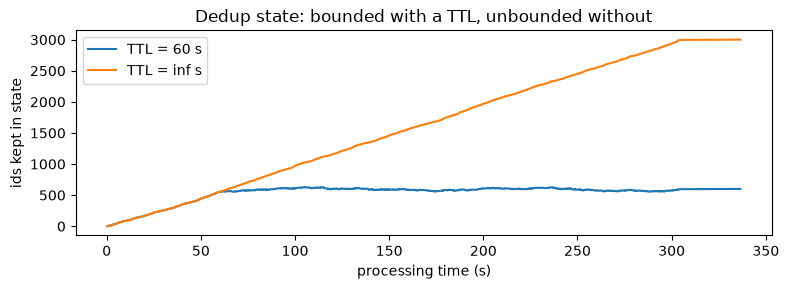

In [11]:
class Deduplicator:
    def __init__(self, ttl, bound=0):
        self.ttl, self.bound = ttl, bound
        self.seen, self.expiry = {}, []                # event_id -> event time; min-heap of (event time, id)
        self.max_t, self.trace = -math.inf, []
    def process(self, e):
        self.max_t = max(self.max_t, e.event_time)
        wm = self.max_t - self.bound
        while self.expiry and self.expiry[0][0] + self.ttl < wm:   # evict expired ids (cheap with a heap)
            _, old = heapq.heappop(self.expiry)
            self.seen.pop(old, None)
        if e.event_id in self.seen:
            self.trace.append((e.arrival, len(self.seen)))
            return None                                # duplicate: drop it
        self.seen[e.event_id] = e.event_time
        heapq.heappush(self.expiry, (e.event_time, e.event_id))
        self.trace.append((e.arrival, len(self.seen)))   # state size after this event
        return e

true_dups = len(stream) - len(clean)
rows, traces = [], {}
for ttl in [1, 5, 60, math.inf]:
    d = Deduplicator(ttl)
    out = [x for e in stream if (x := d.process(e)) is not None]
    rows.append({"TTL (s)": ttl, "duplicates removed": len(stream) - len(out), "missed": true_dups - (len(stream) - len(out)),
                 "ids in state at end": len(d.seen), "max ids in state": max(n for _, n in d.trace)})
    traces[ttl] = d.trace
print(f"true duplicates in the raw stream: {true_dups}")
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3))
for ttl in [60, math.inf]:
    t, n = zip(*traces[ttl]); ax.plot(t, n, label=f"TTL = {ttl} s")
ax.set_xlabel("processing time (s)"); ax.set_ylabel("ids kept in state"); ax.set_title("Dedup state: bounded with a TTL, unbounded without")
ax.legend(); plt.tight_layout(); plt.show()

**What just happened?** A retry arrives 1–5 s after the original *arrived*, but the original itself may have been up to 40 s late, so in event time a duplicate can come up to about 45 s after its event. Short TTLs (1 s, 5 s) therefore let duplicates through. A TTL of 60 s catches all of them while keeping only the last minute of IDs: the state levels off in the plot. Without a TTL the set grows with the stream, forever. **The TTL must cover the maximum delay plus the retry interval.** For very high volumes, a **Bloom filter** per time bucket replaces the exact set ([`dsa/04`](../../00_AI_Fundamentals/dsa/04_hashing.ipynb)).

### 4.3 Stream–table joins (temporal joins)

Events are often **enriched** with data from a table: the user's subscription tier, a product's price. The table changes over time, so the right question is "what was the tier **when the event happened**?" (a **temporal join**, "as of" event time), not "what is it **now**?". We keep the table's history in SQLite, as a change-data-capture (CDC) feed would deliver it.

In [12]:
rng = np.random.default_rng(3)
users = sorted({e.user for e in clean})
history = [(u, "free", 0.0) for u in users]                                     # everyone starts "free"
for u in rng.choice(users, 40, replace=False):                                 # 40 upgrades at random times
    history.append((u, "pro", round(float(rng.uniform(10, 290)), 3)))
db = sqlite3.connect(WORK / "dims.db")
db.execute("CREATE TABLE user_tier (user TEXT, tier TEXT, valid_from REAL)")
db.executemany("INSERT INTO user_tier VALUES (?, ?, ?)", history)
db.commit()

versions = defaultdict(list)                                                   # user -> sorted [(valid_from, tier)]
for u, tier, vf in db.execute("SELECT user, tier, valid_from FROM user_tier ORDER BY user, valid_from"):
    versions[u].append((vf, tier))

def tier_as_of(user, t):
    v = versions[user]
    i = bisect.bisect_right([vf for vf, _ in v], t) - 1                        # last version with valid_from <= t
    return v[i][1]

temporal = [tier_as_of(e.user, e.event_time) for e in clean]                   # as of EVENT time (correct)
naive = [tier_as_of(e.user, e.arrival) for e in clean]                         # as of processing time (naive lookup)

left = pd.DataFrame(clean).sort_values("event_time")
right = pd.DataFrame(history, columns=["user", "tier", "valid_from"]).sort_values("valid_from")
asof = pd.merge_asof(left, right, left_on="event_time", right_on="valid_from", by="user")
assert dict(zip(asof.event_id, asof.tier)) == {e.event_id: t for e, t in zip(clean, temporal)}
diff = sum(a != b for a, b in zip(temporal, naive))
print(f"temporal join matches pandas.merge_asof; a processing-time lookup gives a different tier for {diff} events")

temporal join matches pandas.merge_asof; a processing-time lookup gives a different tier for 2 events


**What just happened?** The temporal join (bisect into each user's version list) equals `pandas.merge_asof`, the batch definition of an as-of join. A naive "look up the current value when the event arrives" disagrees for the few events that were still in flight when their user upgraded (only a handful here; in a system with millions of events and frequent table updates, many more). For ML features this difference is a source of **training–serving skew** and **label leakage** (using information from the future), the problem feature stores solve with point-in-time joins ([feature stores](../../15_MLOps/12_feature_stores.ipynb)).

---
## 5. Delivery semantics, idempotent sinks and checkpoints

> 💬 **In plain English:** after a crash, make sure nothing is lost and nothing is counted twice.

A stream source such as a **Kafka partition** is an append-only **log**: each record has an **offset** (0, 1, 2, …). A consumer reads from its last **committed offset**, processes a batch, writes results to a sink, and commits the new offset. A crash can happen between any two steps; on restart, the consumer resumes from the last committed offset. The order of "write" and "commit" decides the guarantee:

| guarantee | order of steps | after a crash between the steps |
|---|---|---|
| **at-most-once** | commit offset, then write | the batch is **lost** (never written, never re-read) |
| **at-least-once** | write, then commit offset | the batch is **re-read and written again**: duplicates |
| **exactly-once** (effectively once) | at-least-once + **idempotent** sink, or write results **and** offset in **one transaction** | duplicates are ignored / the half-done batch is rolled back |

"Exactly-once" does not mean each event is *processed* once (after a crash it may be processed twice); it means each event **affects the final result** once.

We replay the purchase events as a log of offsets and crash each consumer once, right between the two steps.

In [13]:
log = [e for e in clean if e.kind == "purchase"]                       # the topic partition: offsets 0..n-1
TRUE_REVENUE = round(sum(e.amount for e in log), 2)

class SimulatedCrash(Exception):
    pass

def make_db(path, idempotent):
    con = sqlite3.connect(path, isolation_level=None)                  # autocommit; we control transactions
    pk = "PRIMARY KEY" if idempotent else ""
    con.execute(f"CREATE TABLE IF NOT EXISTS sink (event_id TEXT {pk}, user TEXT, amount REAL)")
    con.execute("CREATE TABLE IF NOT EXISTS offsets (consumer TEXT PRIMARY KEY, next_offset INTEGER)")
    return con

def committed(con):
    row = con.execute("SELECT next_offset FROM offsets WHERE consumer = 'c1'").fetchone()
    return row[0] if row else 0

def commit(con, off):
    con.execute("INSERT OR REPLACE INTO offsets VALUES ('c1', ?)", (off,))

def write(con, batch, idempotent):
    verb = "INSERT OR IGNORE" if idempotent else "INSERT"              # idempotent: re-inserting a key is a no-op
    con.executemany(f"{verb} INTO sink VALUES (?, ?, ?)", [(e.event_id, e.user, e.amount) for e in batch])

def consume(con, mode, crash_at=None, batch_size=20):
    off = committed(con)                                               # resume from the last committed offset
    while off < len(log):
        batch, nxt = log[off:off + batch_size], min(off + batch_size, len(log))
        crash = crash_at is not None and off == crash_at
        if mode == "at-most-once":
            commit(con, nxt)
            if crash: raise SimulatedCrash
            write(con, batch, idempotent=False)
        elif mode in ("at-least-once", "at-least-once + idempotent sink"):
            write(con, batch, idempotent=(mode != "at-least-once"))
            if crash: raise SimulatedCrash
            commit(con, nxt)
        elif mode == "transactional (results + offset atomically)":
            con.execute("BEGIN")
            try:
                write(con, batch, idempotent=False)
                if crash: raise SimulatedCrash
                commit(con, nxt)
                con.execute("COMMIT")
            except SimulatedCrash:
                con.execute("ROLLBACK")                               # the half-done batch disappears
                raise
        off = nxt

rows = []
for mode in ["at-most-once", "at-least-once", "at-least-once + idempotent sink", "transactional (results + offset atomically)"]:
    path = WORK / f"sink_{len(rows)}.db"
    con = make_db(path, idempotent="idempotent" in mode)
    try:
        consume(con, mode, crash_at=100)                               # first run crashes at offset 100
    except SimulatedCrash:
        pass
    con.close()
    con = make_db(path, idempotent="idempotent" in mode)               # "restart the process"
    consume(con, mode)                                                 # resume and finish
    n, distinct, revenue = con.execute("SELECT COUNT(*), COUNT(DISTINCT event_id), ROUND(SUM(amount), 2) FROM sink").fetchone()
    rows.append({"mode": mode, "rows in sink": n, "lost events": len(log) - distinct,
                 "duplicate rows": n - distinct, "revenue error": round(revenue - TRUE_REVENUE, 2)})
    con.close()
print(f"log has {len(log)} purchase events, true revenue {TRUE_REVENUE}")
print(pd.DataFrame(rows).to_string(index=False))

log has 258 purchase events, true revenue 7824.34
                                       mode  rows in sink  lost events  duplicate rows  revenue error
                               at-most-once           238           20               0        -731.02
                              at-least-once           278            0              20         731.02
            at-least-once + idempotent sink           258            0               0           0.00
transactional (results + offset atomically)           258            0               0           0.00


**What just happened?** Each consumer crashed once, at offset 100, between its two steps, then restarted:

- **at-most-once** committed first, so the batch at offsets 100–119 was never written: 20 events **lost**.
- **at-least-once** wrote first, so after the restart the same batch was written again: 20 **duplicate** rows and an inflated revenue.
- **at-least-once + idempotent sink**: the replayed rows had the same primary key, and `INSERT OR IGNORE` made the second write a no-op: correct.
- **transactional**: the batch and the offset were in one SQLite transaction; the crash rolled both back, and the restart redid the batch once: correct.

These are exactly the two ways real systems get end-to-end exactly-once: **idempotent writes** (upserts keyed by an event ID) or **atomic commit of output and progress** (Kafka transactions, Flink's two-phase-commit sinks), on top of a **replayable source**.

### 5.1 Checkpointing operator state

Stateful operators also lose their state in a crash. The remedy is a **checkpoint**: periodically save the operator state **together with the source offset**, atomically. After a crash, load the last checkpoint and **replay** the log from its offset. Results emitted between the checkpoint and the crash are emitted again, so the sink must be idempotent (here: an upsert keyed by window). Flink takes such checkpoints consistently across many parallel operators with **barriers** injected into the stream (the Chandy–Lamport snapshot idea).

In [14]:
def snapshot(op):
    return json.dumps({"max_t": op.max_t, "dropped": op.dropped,
                       "state": [[list(w), c] for w, c in op.state.items()], "fired": [list(w) for w in op.fired]})

def restore(op, blob):
    s = json.loads(blob)
    op.max_t, op.dropped = s["max_t"], s["dropped"]
    op.state = {tuple(w): c for w, c in s["state"]}
    op.fired = {tuple(w) for w in s["fired"]}

def run_with_checkpoints(events, ckpt_db, sink, crash_at=None, every=300):
    # Tumbling 10 s counts, bound 5 s, allowed lateness 30 s; sink = dict window -> count (upsert).
    op = WindowedCount(tumble10, bound=5, lateness=30, emit=lambda w, c, now, kind: sink.__setitem__(w, c))
    row = ckpt_db.execute("SELECT offset, state FROM ckpt ORDER BY offset DESC LIMIT 1").fetchone()
    start = 0
    if row:                                                     # recovery path
        start = row[0]; restore(op, row[1])
    for off in range(start, len(events)):
        if crash_at is not None and off == crash_at:
            raise SimulatedCrash
        op.process(events[off])
        if (off + 1) % every == 0:                              # checkpoint: state + next offset, atomically
            with ckpt_db:
                ckpt_db.execute("INSERT INTO ckpt VALUES (?, ?)", (off + 1, snapshot(op)))
    op.flush(events[-1].arrival)
    return op

def fresh_ckpt_db(name):
    c = sqlite3.connect(WORK / name)
    c.execute("CREATE TABLE ckpt (offset INTEGER, state TEXT)")
    return c

ref_sink = {}
run_with_checkpoints(clean, fresh_ckpt_db("ckpt_ref.db"), ref_sink)        # no crash

sink, ckdb = {}, fresh_ckpt_db("ckpt_crash.db")
try:
    run_with_checkpoints(clean, ckdb, sink, crash_at=1234)                  # crash mid-stream
except SimulatedCrash:
    print("crashed at offset 1234; last checkpoint at offset", ckdb.execute("SELECT MAX(offset) FROM ckpt").fetchone()[0])
run_with_checkpoints(clean, ckdb, sink)                                    # restart: restore + replay
assert sink == ref_sink
print(f"after recovery: {len(sink)} window results, identical to the run without a crash")

crashed at offset 1234; last checkpoint at offset 1200
after recovery: 31 window results, identical to the run without a crash


**What just happened?** The operator crashed at offset 1234; the last checkpoint was at offset 1200. On restart it restored the window state from that checkpoint, replayed offsets 1200 onward, and re-emitted some window results, which the upsert sink simply overwrote. The final results equal the crash-free run exactly. Without the checkpoint, restarting from offset 0 would also work but would take as long as the whole history; restarting from the committed offset **without** the state would silently produce wrong counts.

---
## 6. Backpressure with bounded queues (`asyncio`)

> 💬 **In plain English:** when the next step is slow, make the fast step wait instead of piling up work.

If a producer is faster than its consumer, events pile up somewhere. With an **unbounded** queue, memory grows until the process dies. **Backpressure** means the slow stage pushes back on the fast one: with a **bounded** queue, `put()` waits when the queue is full, so the producer automatically slows to the consumer's speed. The alternatives are **dropping** or **sampling** events (load shedding) or **scaling out** the consumer.

We use `asyncio` (cooperative concurrency in one thread): a producer emits one event per millisecond, a consumer needs three milliseconds per event.

       queue  max queue length  producer finished (s)  consumer finished (s)
   unbounded               133                   0.23                   0.65
bounded (20)                20                   0.59                   0.66


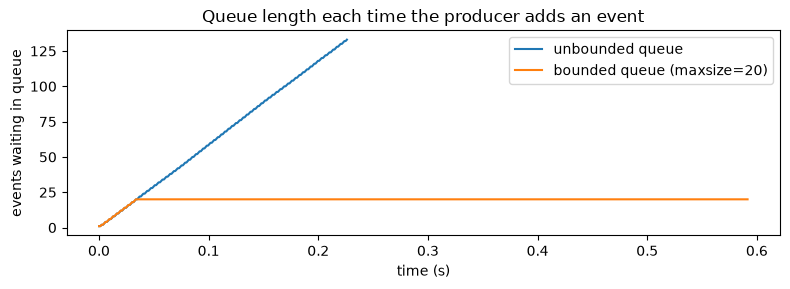

In [15]:
async def pipeline(maxsize, n=200, produce_every=0.001, consume_cost=0.003):
    q = asyncio.Queue(maxsize=maxsize)              # maxsize=0 means unbounded
    trace, t0, done = [], time.perf_counter(), {}
    async def producer():
        for i in range(n):
            await q.put(i)                          # waits here while the queue is full: backpressure
            trace.append((time.perf_counter() - t0, q.qsize()))
            await asyncio.sleep(produce_every)
        await q.put(None)
        done["producer"] = time.perf_counter() - t0
    async def consumer():
        while (item := await q.get()) is not None:
            await asyncio.sleep(consume_cost)       # a slow sink (e.g. a database write)
        done["consumer"] = time.perf_counter() - t0
    await asyncio.gather(producer(), consumer())
    return trace, done

results_bp = {}
for maxsize in [0, 20]:
    results_bp[maxsize] = await pipeline(maxsize)   # top-level await works in Jupyter
summary = pd.DataFrame([{"queue": "unbounded" if m == 0 else f"bounded ({m})",
                         "max queue length": max(s for _, s in tr),
                         "producer finished (s)": round(d["producer"], 2), "consumer finished (s)": round(d["consumer"], 2)}
                        for m, (tr, d) in results_bp.items()])
print(summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3))
for m, (tr, _) in results_bp.items():
    t, s = zip(*tr); ax.plot(t, s, label="unbounded queue" if m == 0 else f"bounded queue (maxsize={m})")
ax.set_xlabel("time (s)"); ax.set_ylabel("events waiting in queue"); ax.set_title("Queue length each time the producer adds an event")
ax.legend(); plt.tight_layout(); plt.show()

**What just happened?** With the unbounded queue, the producer finished early and the backlog grew to well over a hundred events: with an endless stream it would grow until memory runs out. With `maxsize=20` the backlog never exceeds 20; the producer was slowed down to the consumer's pace and finished at about the same time as the consumer. The consumer finishes at roughly the same time in both cases, because it is the bottleneck either way: backpressure does not make a slow system faster, it makes it **stable**.

In real systems backpressure appears as Kafka's **pull** model (consumers fetch only what they can handle, and the backlog waits safely on the broker's disk as **consumer lag**), Flink's credit-based flow control between operators, and Spark's `maxOffsetsPerTrigger`. Consumer lag is the key metric to monitor and alert on.

---
## 7. Streaming features for online ML

> 💬 **In plain English:** features for live models must be computed exactly the same way as the features used for training.

Real-time ML models (fraud, ads, recommendations) need **fresh features** such as "number of events by this user in the last 60 seconds" or "amount spent in the last 5 minutes". These are sliding-window aggregates computed **per event**. Two requirements:

1. **Point-in-time correctness**: a feature for an event at time $t$ may only use events with time $< t$ (no peeking at the future).
2. **Training–serving consistency**: the online (streaming) computation must give the same values as the offline (batch) computation used to build training data, otherwise the model sees different inputs in production (**training–serving skew**).

We compute both features online with a small **reorder buffer** (release events in event-time order once the watermark passes them) and a per-user deque, and compare with a batch computation in pandas/NumPy.

In [16]:
def reorder(events, bound):
    # Release events in event-time order once the watermark (max event time - bound) passes them.
    heap, max_t, dropped, last_out = [], -math.inf, 0, -math.inf
    for e in events:
        if e.event_time < last_out:                    # older than something already released: too late
            dropped += 1
            continue
        heapq.heappush(heap, (e.event_time, e.event_id, e))
        max_t = max(max_t, e.event_time)
        while heap and heap[0][0] <= max_t - bound:
            last_out = heap[0][0]
            yield heapq.heappop(heap)[2]
    while heap:
        yield heapq.heappop(heap)[2]

def online_features(ordered_events):
    recent = defaultdict(deque)                        # user -> deque of (event_time, amount) within 300 s
    feats = {}
    for e in ordered_events:
        dq = recent[e.user]
        while dq and dq[0][0] <= e.event_time - 300:   # expire events older than 5 minutes
            dq.popleft()
        n60 = sum(1 for t, _ in dq if t > e.event_time - 60)
        spend300 = round(sum(a for _, a in dq), 2)
        feats[e.event_id] = (n60, spend300)            # computed BEFORE adding the current event
        dq.append((e.event_time, e.amount))
    return feats

def batch_features(events):
    d = pd.DataFrame(events).sort_values("event_time")
    out = {}
    for _, g in d.groupby("user"):
        t, a = g.event_time.to_numpy(), g.amount.to_numpy()
        csum = np.r_[0, np.cumsum(a)]
        i = np.arange(len(t))
        lo60 = np.searchsorted(t, t - 60, side="right")      # first event with time > t - 60
        lo300 = np.searchsorted(t, t - 300, side="right")
        for k, eid in enumerate(g.event_id):
            out[eid] = (int(i[k] - lo60[k]), round(float(csum[i[k]] - csum[lo300[k]]), 2))
    return out

offline = batch_features(clean)
rows = []
for name, ordered in [("arrival order (no reordering)", iter(clean)),
                      ("reorder buffer, bound 2 s", reorder(clean, 2)),
                      ("reorder buffer, bound 45 s", reorder(clean, 45))]:
    online = online_features(ordered)
    mismatch = sum(1 for k, v in online.items() if not (v[0] == offline[k][0] and math.isclose(v[1], offline[k][1], abs_tol=0.01)))
    rows.append({"online computation": name, "events with features": len(online),
                 "features different from batch": mismatch, "share": f"{mismatch / len(clean):.1%}"})
print(pd.DataFrame(rows).to_string(index=False))

           online computation  events with features  features different from batch share
arrival order (no reordering)                  3000                            653 21.8%
    reorder buffer, bound 2 s                  2928                            915 30.5%
   reorder buffer, bound 45 s                  3000                              0  0.0%


**What just happened?** Computing features in arrival order gives values that differ from the batch (training) values for about a fifth of the events: a late event is counted as if it were recent, and an event that arrives early "sees" fewer predecessors. Surprisingly, a reorder buffer with a **small** bound is even worse here: it **drops** the late events, so every later feature of that user over the next 5 minutes is missing them. Only a bound larger than the largest delay reproduces the batch features exactly, and then each feature is available only about 45 s after its event. In practice teams either accept a measured, small mismatch, or build the training features by **replaying the logged stream through the very same online code**, so that training and serving are consistent by construction. Production systems balance this per feature, and feature stores record the event time of every feature value so that training data can be rebuilt **point-in-time correctly** ([feature stores](../../15_MLOps/12_feature_stores.ipynb), [online learning](../../03_Machine_Learning/12_online_learning/01_online_learning.ipynb), [streaming model updates](../../03_Machine_Learning/12_online_learning/02_industry_streaming_model_updates.ipynb)).

---
## 8. How Kafka, Flink and Spark Structured Streaming map to this

> 💬 **In plain English:** every piece built here has a name in the real tools.

| concept | this notebook | Apache Kafka | Apache Flink | Spark Structured Streaming | Kafka Streams |
|---|---|---|---|---|---|
| durable, replayable source | `log` list with offsets | topic partitions, consumer-group offsets | Kafka source, offsets stored in checkpoints | Kafka source, offsets in the checkpoint location | input topics |
| event time + watermark | `max_t - bound` | record timestamps | `WatermarkStrategy.forBoundedOutOfOrderness` | `withWatermark("ts", "10 seconds")` | stream time + grace period |
| windows | `tumbling`, `sliding`, `SessionWindows` | — | tumbling / sliding / session event-time windows | `window()`, `session_window()` | `TimeWindows`, `SlidingWindows`, `SessionWindows` |
| late data | `lateness`, `dropped` | — | `allowedLateness`, `sideOutputLateData` | dropped once older than the watermark | `grace()` |
| keyed state | Python dicts | — | keyed state (heap or RocksDB backend) | state store (RocksDB option) | state stores backed by changelog topics |
| fault tolerance | SQLite checkpoint + replay | committed offsets, replication | distributed snapshots (checkpoint barriers) | checkpoint + write-ahead offset log | changelog topics |
| exactly-once output | idempotent upsert / transaction | idempotent producer + transactions | two-phase-commit sinks | idempotent / transactional sinks (e.g. Delta) | `processing.guarantee = exactly_once_v2` |
| backpressure | bounded `asyncio.Queue` | pull-based consumers, consumer lag | credit-based flow control | `maxOffsetsPerTrigger` | pull-based |
| processing model | one event at a time | (transport only) | true streaming, one event at a time | micro-batches (continuous mode experimental) | one record at a time |

The Kafka cluster itself is the **transport and storage** layer; Flink, Spark and Kafka Streams are **processing** engines that read from it. Cloud equivalents: Amazon Kinesis, Google Pub/Sub + Dataflow (Apache Beam), Azure Event Hubs + Stream Analytics. See also [message queues](../../16_Deployment/message_queues/01_message_queues.ipynb) and [time-series databases](../08_time_series_databases/01_time_series_databases.ipynb), which often store the results.

---
## 9. 🔗 How this connects to modern AI

> 💬 **In plain English:** the same machinery feeds fresh data to fraud, ads and LLM systems.

- **Real-time features for ML models.** Fraud detection, ad click prediction and recommendations depend on features like "transactions in the last 10 minutes", computed by exactly these windowed, stateful, exactly-once operators and served from an online feature store ([feature stores](../../15_MLOps/12_feature_stores.ipynb), [fraud detection](../../03_Machine_Learning/08_anomaly_detection/02_industry_fraud_detection.ipynb)).
- **Online learning and drift monitoring.** Models updated on streams, and drift detectors watching prediction distributions, consume windowed aggregates ([online learning](../../03_Machine_Learning/12_online_learning/01_online_learning.ipynb), [monitoring](../../15_MLOps/06_monitoring/01_monitoring.ipynb)).
- **LLM applications.** Token streaming to users uses backpressure-aware async generators; LLM gateways aggregate per-user token usage in tumbling windows for rate limiting and billing, where exactly-once matters because it is money ([LLMOps](../../15_MLOps/13_llmops.ipynb)).
- **RAG freshness.** Change-data-capture streams from databases keep vector indexes up to date: a stream–table join plus an idempotent upsert into the vector store ([RAG pipeline](../../08_LLM/19_industry_rag_pipeline.ipynb)).
- **Approximate streaming analytics.** When exact state is too large, sketches (HyperLogLog, Count-Min) replace the dictionaries used here ([advanced algorithms 06](../../00_AI_Fundamentals/advanced_algorithms/06_streaming_and_sketching_algorithms.ipynb)).

---
## 10. Recap

- Streams are **unbounded**; events carry an **event time** and arrive at a **processing time**; real streams are **out of order** and contain **late** events and **duplicates**.
- **Tumbling** (no overlap), **sliding** (overlapping, $s/d$ windows per event) and **session** (gap-based, per key, mergeable) windows group a stream by event time.
- A **watermark** $W = \max t - \text{bound}$ declares "everything before $W$ has arrived"; windows fire when $W \ge$ end. A larger bound means more complete but later results; **allowed lateness** emits early results plus corrections (needs an upsert sink).
- Stateful operators must keep **bounded** state: purge windows after the lateness horizon, expire dedup IDs with a **TTL**. Join with tables **as of event time** (temporal join).
- **At-most-once** = commit then write (loss); **at-least-once** = write then commit (duplicates); **exactly-once** = at-least-once + **idempotent sink**, or results and offsets in **one transaction**, over a **replayable source**.
- **Checkpoints** save operator state with the source offset; recovery = restore + replay (+ idempotent sink).
- **Backpressure** via bounded queues keeps memory stable when a stage is slow; monitor **consumer lag**.
- Online ML features must be **point-in-time correct** and match the batch computation, or the model suffers training–serving skew.

## Practice problems

Solutions are hidden; try first. Every code solution was run and tested when this notebook was built.

**1. (Easy, conceptual)** A mobile game records "coins bought" events on the phone and uploads them when the phone is online. Should the "revenue per hour" dashboard use event time or processing time? What happens to yesterday's 23:00–24:00 figure when a phone comes online this morning?

<details><summary>Show solution</summary>

**Event time**: revenue belongs to the hour in which the purchase happened. When the phone uploads this morning, its events are late for yesterday's 23:00 window. With allowed lateness (or a batch correction job), the 23:00 figure is **updated** upwards; with a watermark and no lateness, those events are dropped or sent to a side output for a separate correction. With processing time they would wrongly be counted in this morning's hour, and replaying the stream would give different numbers.

</details>

**2. (Easy, conceptual)** Tumbling windows of 10 s, watermark bound 5 s. Events arrive with event times 2, 7, 13, 4, 16, 9, 21 (in this order). When does window [0, 10) fire, with which count, and which events are late?

<details><summary>Show solution</summary>

Watermarks after each arrival: −3, 2, 8, 8, 11, 11, 16. The window [0, 10) fires when the watermark first reaches 10, i.e. after the event at 16 (W = 11). By then it contains 2, 7 and 4: **count 3**. The event at 9 arrives after the firing (W = 11 > 9), so it is **late**. With no allowed lateness it is dropped. With allowed lateness $L$ the window's state is kept until $W \ge 10 + L$; since $W = 11$ when the event arrives, it is accepted (and an updated count of 4 is emitted) only if $L > 1$ s.

</details>

**3. (Medium, coding)** Write `hopping_count(times, size, slide)` that returns a `Counter` of window → count for a **batch** of event times using `sliding()`, and check it against a brute-force double loop on random times.

<details><summary>Show solution</summary>

```python
def hopping_count(times, size, slide):
    return Counter(w for t in times for w in sliding(t, size, slide))

ts = np.random.default_rng(5).uniform(0, 200, 500)
got = hopping_count(ts, 30, 10)
brute = Counter()
for s in range(-30, 230, 10):
    n = int(((ts >= s) & (ts < s + 30)).sum())
    if n:
        brute[(s, s + 30)] = n
assert got == brute
```

</details>

**4. (Medium, conceptual)** Your consumer writes each batch to a sink that **increments counters** (`UPDATE stats SET clicks = clicks + n`), then commits the offset. Which guarantee do you have, why is the result wrong after a crash, and give two fixes.

<details><summary>Show solution</summary>

Write-then-commit is **at-least-once**; increments are **not idempotent**, so a replayed batch is added twice. Fixes: (1) make the write idempotent, e.g. store per-batch or per-event rows keyed by an ID (`INSERT OR IGNORE`) and compute totals from them, or store `(window, count)` with an **upsert** of the full value instead of an increment; (2) write the increments **and** the new offset in **one transaction** (both or neither), as in the transactional mode; (3) in Kafka-to-Kafka pipelines, use Kafka transactions / `exactly_once_v2`.

</details>

**5. (Medium, coding)** Implement `dedup_ttl(events, ttl)` for a list of `(event_id, t)` pairs in **event-time order** (no watermark bound needed) that drops an event if the same ID was seen within the last `ttl` seconds, using an `OrderedDict` for O(1) expiry. Test it on a small example and against a brute-force version on random data.

<details><summary>Show solution</summary>

```python
from collections import OrderedDict

def dedup_ttl(events, ttl):
    seen, out = OrderedDict(), []                    # id -> time first seen, oldest first
    for eid, t in events:
        while seen and next(iter(seen.values())) < t - ttl:
            seen.popitem(last=False)                 # expire the oldest id
        if eid not in seen:
            seen[eid] = t
            out.append((eid, t))
    return out

def dedup_brute(events, ttl):
    out, kept = [], []                               # kept: (id, time) of events that were let through
    for eid, t in events:
        if not any(k == eid and t - kt <= ttl for k, kt in kept):
            kept.append((eid, t)); out.append((eid, t))
    return out

assert dedup_ttl([("a", 0), ("a", 3), ("b", 4), ("a", 12)], ttl=10) == [("a", 0), ("b", 4), ("a", 12)]
r = np.random.default_rng(2)
ev = sorted(((f"id{r.integers(0, 30)}", float(t)) for t in r.uniform(0, 100, 400)), key=lambda x: x[1])
assert dedup_ttl(ev, 7) == dedup_brute(ev, 7)
```

Events arrive in time order, so the dict's insertion order is also time order and the oldest entry is always first.

</details>

**6. (Medium, conceptual)** Explain why Spark Structured Streaming's **append** output mode for a windowed aggregation needs a watermark, while **update** mode does not.

<details><summary>Show solution</summary>

Append mode emits each result row **once and never changes it**, so a window can only be emitted when it is final; without a watermark Spark can never know a window is final (a late event could always arrive), so it would never emit anything, and Spark rejects such a query. Update mode emits the current value of every window that changed in each micro-batch, so results can be revised later; a watermark is still recommended there to **bound the state**, otherwise all windows are kept forever.

</details>

**7. (Hard, coding)** Write `sessionize(times, gap)` that turns one user's **unsorted** event times into a list of `(start, end, count)` sessions (a new session starts when the gap to the previous event is ≥ `gap`). Check it against `SessionWindows` on the events of user `u000` from the stream.

<details><summary>Show solution</summary>

```python
def sessionize(times, gap):
    times = sorted(times)
    out, start, prev, n = [], times[0], times[0], 1
    for t in times[1:]:
        if t - prev >= gap:
            out.append((start, prev, n)); start, n = t, 0
        prev, n = t, n + 1
    out.append((start, prev, n))
    return out

u_events = [e for e in clean if e.user == "u000"]
sw = SessionWindows(gap=15, bound=45)
for e in u_events:
    sw.process(e)
sw.flush()
assert sessionize([e.event_time for e in u_events], 15) == sorted((a, b, n) for _, a, b, n in sw.out)
```

</details>

## Further reading (additional learning resources)

- Akidau et al., "The Dataflow Model: A Practical Approach to Balancing Correctness, Latency, and Cost in Massive-Scale, Unbounded, Out-of-Order Data Processing", VLDB 2015.
- Akidau, Chernyak & Lax, *Streaming Systems* (O'Reilly, 2018); and Tyler Akidau's free essays "Streaming 101" and "Streaming 102" (O'Reilly Radar).
- Kleppmann, *Designing Data-Intensive Applications*, ch. 11 (stream processing: event time, windows, joins, exactly-once).
- Carbone et al., "Lightweight Asynchronous Snapshots for Distributed Dataflows", 2015 (Flink checkpoints); Chandy & Lamport, "Distributed Snapshots", 1985.
- Apache Flink documentation: "Timely stream processing" and "Fault tolerance": https://nightlies.apache.org/flink/flink-docs-stable/
- GeeksforGeeks: [What is Apache Kafka?](https://www.geeksforgeeks.org/apache-kafka/), [Difference between batch processing and stream processing](https://www.geeksforgeeks.org/difference-between-batch-processing-and-stream-processing/).

## Next notebook
➡️ [Feature stores](../../15_MLOps/12_feature_stores.ipynb): storing the streaming and batch features you just computed, with point-in-time-correct training data. To revisit Spark's streaming API, see [03 · Spark locally](03_spark_locally.ipynb).

In [17]:
db.close(); ckdb.close()
shutil.rmtree(WORK, ignore_errors=True)
print("temporary folder removed:", not WORK.exists())

temporary folder removed: True
